# 
Train/Test Split & Model Selection


##  Import libraries

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

DATA_PATH = 'England_Wales_Electricity_2021_2025_for_prediction.csv'

In [15]:
# Ensure folders exist (run this if you get FileNotFoundError below)
import os
os.makedirs('../data', exist_ok=True)
os.makedirs('../outputs', exist_ok=True)
os.makedirs('../plots', exist_ok=True)

## Load cleaned data

In [16]:
df = pd.read_csv(DATA_PATH, parse_dates=['Date', 'Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)
print('Shape:', df.shape)
df.head()

Shape: (86976, 27)


,Date,Time_Period,Electricity_Demand,Wind_Generation,Wind_Capacity,Solar_Generation,Solar_Capacity,Year,Month,Day,...,Demand_Previous_1hr,Demand_Previous_24hr,Demand_Previous_7days,Datetime,Hour_sin,Hour_cos,Month_sin,Month_cos,DoW_sin,DoW_cos
0,2021-01-15,1,25826,699,6527,0,13527,2021,1,15,...,27107.0,24797.0,27155.0,2021-01-15 00:00:00,0.000000,1.000000,0.5,0.866025,-0.433884,-0.900969
1,2021-01-15,2,26297,703,6527,0,13527,2021,1,15,...,25972.0,25251.0,27557.0,2021-01-15 00:30:00,0.000000,1.000000,0.5,0.866025,-0.433884,-0.900969
2,2021-01-15,3,26133,624,6527,0,13527,2021,1,15,...,25826.0,24932.0,27375.0,2021-01-15 01:00:00,0.258819,0.965926,0.5,0.866025,-0.433884,-0.900969
3,2021-01-15,4,25682,571,6527,0,13527,2021,1,15,...,26297.0,24397.0,26883.0,2021-01-15 01:30:00,0.258819,0.965926,0.5,0.866025,-0.433884,-0.900969
4,2021-01-15,5,25363,548,6527,0,13527,2021,1,15,...,26133.0,23964.0,26335.0,2021-01-15 02:00:00,0.500000,0.866025,0.5,0.866025,-0.433884,-0.900969


## Select features (day-ahead safe — no leakage)



In [17]:
feature_cols = [
    'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DoW_sin', 'DoW_cos',
    'Is_Weekend', 'Quarter', 'Year', 'Wind_Capacity', 'Solar_Capacity',
    'Demand_Previous_24hr', 'Demand_Previous_7days',
]
target_col = 'Electricity_Demand'

df = df.dropna(subset=feature_cols + [target_col]).reset_index(drop=True)
print('Features:', feature_cols)
print('Rows after dropna:', len(df))

Features: ['Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DoW_sin', 'DoW_cos', 'Is_Weekend', 'Quarter', 'Year', 'Wind_Capacity', 'Solar_Capacity', 'Demand_Previous_24hr', 'Demand_Previous_7days']
Rows after dropna: 86976


##  Time-based train/test split



In [18]:
split_date = df['Datetime'].max() - pd.Timedelta(days=90)
train = df[df['Datetime'] <= split_date]
test = df[df['Datetime'] > split_date]

X_train, y_train = train[feature_cols], train[target_col]
X_test, y_test = test[feature_cols], test[target_col]

print(f'Train: {len(train)} rows ({train["Datetime"].min()} to {train["Datetime"].max()})')
print(f'Test:  {len(test)} rows ({test["Datetime"].min()} to {test["Datetime"].max()})')

Train: 82654 rows (2021-01-15 00:00:00 to 2025-10-02 23:30:00)
Test:  4322 rows (2025-10-03 00:00:00 to 2025-12-31 23:30:00)


## Try multiple models



In [19]:
results = {}
trained_models = {}

def evaluate(name, model, X_test, y_test):
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mape = mean_absolute_percentage_error(y_test, pred) * 100
    accuracy = 100 - mape
    results[name] = {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'Accuracy_%': accuracy}
    print(f'{name}: MAE={mae:.1f}  RMSE={rmse:.1f}  MAPE={mape:.2f}%  Accuracy={accuracy:.2f}%')
    return pred

### Model 1: Linear Regression

In [20]:
lr = LinearRegression()
lr.fit(X_train, y_train)
trained_models['LinearRegression'] = lr
pred_lr = evaluate('LinearRegression', lr, X_test, y_test)

LinearRegression: MAE=1353.4  RMSE=1763.8  MAPE=5.15%  Accuracy=94.85%


### Model 2: Random Forest

In [21]:
rf = RandomForestRegressor(n_estimators=300, max_depth=14, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
trained_models['RandomForest'] = rf
pred_rf = evaluate('RandomForest', rf, X_test, y_test)

RandomForest: MAE=1334.7  RMSE=1817.0  MAPE=5.00%  Accuracy=95.00%


## Model 3: Gradient Boosting


In [22]:
gb = HistGradientBoostingRegressor(max_iter=400, max_depth=6, learning_rate=0.05, random_state=42)
gb.fit(X_train, y_train)
trained_models['GradientBoosting'] = gb
pred_gb = evaluate('GradientBoosting', gb, X_test, y_test)

GradientBoosting: MAE=1564.0  RMSE=2153.0  MAPE=5.65%  Accuracy=94.35%


##  Compare all models

In [23]:
results_df = pd.DataFrame(results).T.sort_values('MAPE')
print(results_df.round(2))

results_df.to_csv('../outputs/model_comparison_v2.csv')

                      MAE     RMSE  MAPE  Accuracy_%
RandomForest      1334.73  1816.96  5.00       95.00
LinearRegression  1353.40  1763.79  5.15       94.85
GradientBoosting  1563.96  2153.04  5.65       94.35


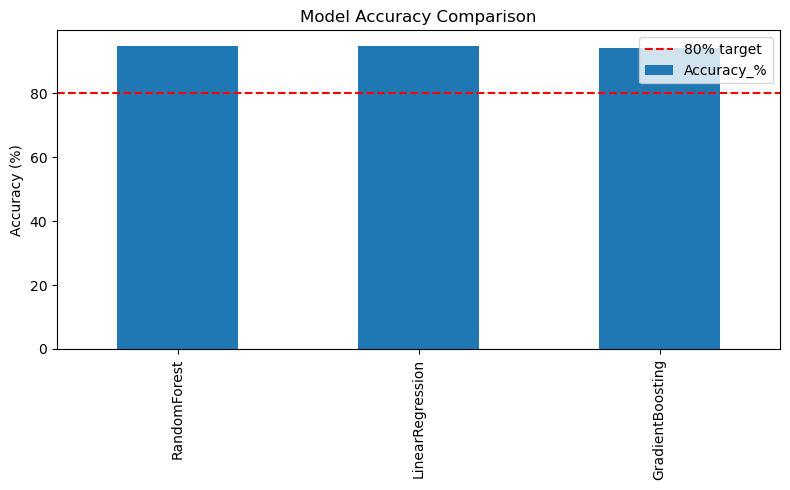

In [24]:
results_df['Accuracy_%'].plot(kind='bar', color='#1f77b4', figsize=(8,5))
plt.axhline(80, color='red', linestyle='--', label='80% target')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.tight_layout(); plt.show()

##  Select the best model

In [25]:
best_model_name = results_df.index[0]
best_accuracy = results_df.loc[best_model_name, 'Accuracy_%']
print(f'Best model: {best_model_name}')
print(f'Accuracy: {best_accuracy:.2f}%')

if best_accuracy >= 80:
    print('Target of 80%+ accuracy ACHIEVED')
else:
    print('Below 80% — consider more features or hyperparameter tuning')

Best model: RandomForest
Accuracy: 95.00%
Target of 80%+ accuracy ACHIEVED


## Save the selection (for Notebook 3 to reuse)

In [26]:
selection = {
    'best_model_name': best_model_name,
    'feature_cols': feature_cols,
    'target_col': target_col,
    'test_metrics': results[best_model_name],
}
with open('../outputs/selected_model.json', 'w') as f:
    json.dump(selection, f, indent=2, default=float)

print('Saved selection to outputs/selected_model.json:')
print(json.dumps(selection, indent=2, default=float))

Saved selection to outputs/selected_model.json:
{
  "best_model_name": "RandomForest",
  "feature_cols": [
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "DoW_sin",
    "DoW_cos",
    "Is_Weekend",
    "Quarter",
    "Year",
    "Wind_Capacity",
    "Solar_Capacity",
    "Demand_Previous_24hr",
    "Demand_Previous_7days"
  ],
  "target_col": "Electricity_Demand",
  "test_metrics": {
    "MAE": 1334.7257133212336,
    "RMSE": 1816.955408597474,
    "MAPE": 4.9998369607456254,
    "Accuracy_%": 95.00016303925437
  }
}
